# Chapter 33: Is Python Getting Faster?

The programs from Chapter 33 of *Data Structures and Algorithms in Python, Hands-On* by Aadhavan Muthurengan, in the book's order. Each code cell is one program; the same program is in this folder as a `.py` file, and its expected output is in the `.out` file with the same name. Benchmark timings differ on every computer and every run.

Run the cells from top to bottom (**Run > Run All Cells**). The programs import each other's files, so keep this notebook in its chapter folder.

## The Suite

`suite.py`

In [1]:
"""A small benchmark suite of this book's kinds of work. Run it with
each Python you have to compare them: python3.12 suite.py, and so on.
With --json, prints the results as JSON instead of a table."""

import heapq
import json
import random
import sys
from collections import deque

import bench

rng = random.Random(2026)
NUMBERS = [rng.random() for _ in range(100_000)]
GRID = 200


def append_loop():
    items = []
    for i in range(100_000):
        items.append(i)


def dict_work():
    d = {}
    for i in range(50_000):
        d[i] = i
    return sum(d[i] for i in range(50_000))


def fib(n):
    return n if n < 2 else fib(n - 1) + fib(n - 2)


def heap_work():
    h = []
    for x in NUMBERS[:50_000]:
        heapq.heappush(h, x)
    while h:
        heapq.heappop(h)


def bfs_grid():
    seen, queue = {(0, 0)}, deque([(0, 0)])
    while queue:
        r, c = queue.popleft()
        for n in ((r + 1, c), (r - 1, c), (r, c + 1), (r, c - 1)):
            if 0 <= n[0] < GRID and 0 <= n[1] < GRID and n not in seen:
                seen.add(n)
                queue.append(n)


class Node:
    __slots__ = ("value", "next")

    def __init__(self, value, next=None):
        self.value, self.next = value, next


def linked_list():
    head = None
    for i in range(50_000):
        head = Node(i, head)
    total = 0
    while head:
        total += head.value
        head = head.next


def insertion_sort():
    items = NUMBERS[:1_500]
    for i in range(1, len(items)):
        x, j = items[i], i - 1
        while j >= 0 and items[j] > x:
            items[j + 1] = items[j]
            j -= 1
        items[j + 1] = x


TESTS = {
    "list append": append_loop,
    "dict set and get": dict_work,
    "recursion (fib 22)": lambda: fib(22),
    "heap push and pop": heap_work,
    "BFS on a grid": bfs_grid,
    "linked list": linked_list,
    "insertion sort": insertion_sort,
    "sorted() 100,000": lambda: sorted(NUMBERS),
}

results = {name: bench.measure(test) for name, test in TESTS.items()}
if "--json" in sys.argv:
    print(json.dumps(results))
else:
    version = ".".join(map(str, sys.version_info[:3]))
    print(f"Python {version}")
    for name, seconds in results.items():
        print(f"{name:>20}: {bench.show_time(seconds)}")

Python 3.15.0
         list append: 2.56 ms
    dict set and get: 4.27 ms
  recursion (fib 22): 1.43 ms
   heap push and pop: 21.2 ms
       BFS on a grid: 20.3 ms
         linked list: 5.69 ms
      insertion sort: 20 ms
    sorted() 100,000: 16 ms


`chart_versions.py`

                        3.12    3.13    3.14    3.15
         list append    1.00    0.86    1.06    0.94
    dict set and get    1.00    0.95    0.92    0.99
  recursion (fib 22)    1.00    0.87    0.79    0.79
   heap push and pop    1.00    0.97    1.04    1.02
       BFS on a grid    1.00    1.10    0.92    0.87
         linked list    1.00    0.85    0.78    0.68
      insertion sort    1.00    1.21    0.86    0.75
    sorted() 100,000    1.00    0.97    1.12    1.08
             overall    1.00    0.97    0.93    0.88


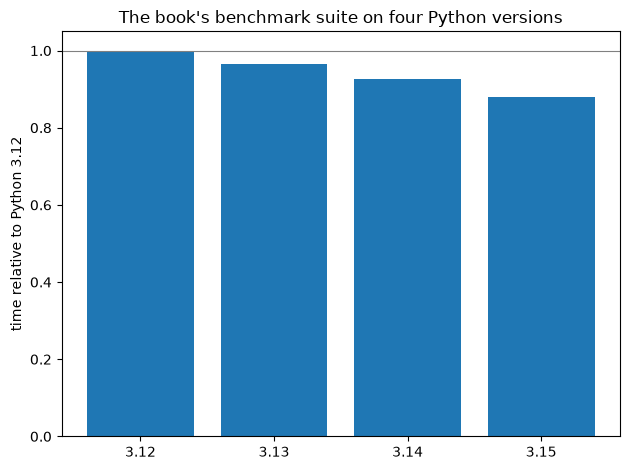

In [2]:
"""Compare the Python versions: each test's time relative to Python
3.12 (below 1.00 is faster), from the results in versions.json."""

import json
from statistics import geometric_mean

import matplotlib.pyplot as plt

with open("versions.json") as f:
    results = json.load(f)
versions = list(results)
base = results[versions[0]]

print(f"{'':>20}" + "".join(f"{v:>8}" for v in versions))
ratios = {v: [] for v in versions}
for test in base:
    row = f"{test:>20}"
    for v in versions:
        ratio = results[v][test] / base[test]
        ratios[v].append(ratio)
        row += f"{ratio:>8.2f}"
    print(row)
overall = {v: geometric_mean(ratios[v]) for v in versions}
print(f"{'overall':>20}" + "".join(f"{overall[v]:>8.2f}" for v in versions))

fig, ax = plt.subplots()
ax.bar(versions, [overall[v] for v in versions])
ax.axhline(1, color="gray", linewidth=0.8)
ax.set_ylabel("time relative to Python 3.12")
ax.set_title("The book's benchmark suite on four Python versions")
fig.tight_layout()
fig.savefig("ch33_versions.png")